# Unit 9: Membangun Model
**Kode unit:** J.62DMI00.013.1 · SKKNI No. 299 Tahun 2020 · Proyek: *Prediksi Arah Harian IHSG*

**Tujuan unit ini:** melatih model, membandingkannya, dan menyimpan model terbaik.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

In [2]:
import joblib
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

latih = pd.read_csv('../data/processed/latih.csv', parse_dates=['Date'])
FITUR_1 = ['ihsg_chg', 'sp500_chg', 'vix_chg', 'oil_chg', 'gold_chg', 'usdidr_chg']   # iterasi 1: dengan kurs
FITUR_2 = ['ihsg_chg', 'sp500_chg', 'vix_chg', 'oil_chg', 'gold_chg']                 # iterasi 2: tanpa kurs
y = latih['target']
cv = TimeSeriesSplit(n_splits=5)

## 1. Menyiapkan model

In [3]:
model_list = {
    'Selalu Naik (baseline)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=20,
                                            class_weight='balanced', random_state=42),
}


def bandingkan(fitur):
    # validasi silang deret waktu untuk semua skenario, dengan daftar fitur tertentu
    X = latih[fitur]
    hasil = []
    for nama, model in model_list.items():
        skor = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro', 'roc_auc'])
        hasil.append({'Model': nama,
                      'Accuracy': skor['test_accuracy'].mean(),
                      'F1-macro': skor['test_f1_macro'].mean(),
                      'ROC-AUC': skor['test_roc_auc'].mean()})

    # baseline aturan: ikuti arah S&P 500
    acc, f1, auc = [], [], []
    for _, idx_val in cv.split(X):
        tebak = (X['sp500_chg'].iloc[idx_val] > 0).astype(int)
        acc.append(accuracy_score(y.iloc[idx_val], tebak))
        f1.append(f1_score(y.iloc[idx_val], tebak, average='macro'))
        auc.append(roc_auc_score(y.iloc[idx_val], X['sp500_chg'].iloc[idx_val]))
    hasil.append({'Model': 'Ikuti S&P 500 (baseline)', 'Accuracy': np.mean(acc), 'F1-macro': np.mean(f1), 'ROC-AUC': np.mean(auc)})
    return pd.DataFrame(hasil).sort_values('Accuracy', ascending=False).reset_index(drop=True)

## 2. Iterasi 1 — 6 fitur (dengan kurs USD/IDR)

In [4]:
hasil_cv_1 = bandingkan(FITUR_1)
hasil_cv_1.round(3)

,Model,Accuracy,F1-macro,ROC-AUC
0,Ikuti S&P 500 (baseline),0.596,0.594,0.632
1,Random Forest,0.595,0.592,0.625
2,Logistic Regression,0.594,0.592,0.632
3,Decision Tree,0.563,0.561,0.600
4,Selalu Naik (baseline),0.541,0.351,0.500


## 3. Iterasi 2 — 5 fitur (tanpa kurs)
Iterasi ini dibuat setelah hasil iterasi 1 ditinjau di Unit 11. Kurs dikeluarkan karena hampir tidak berhubungan
dengan arah IHSG besok (korelasi −0,02 di Unit 3) dan pengaruhnya paling kecil di Random Forest, model terpilih
iterasi 1 (bagian 4).

In [5]:
hasil_cv_2 = bandingkan(FITUR_2)
hasil_cv_2.round(3)

,Model,Accuracy,F1-macro,ROC-AUC
0,Logistic Regression,0.599,0.597,0.632
1,Ikuti S&P 500 (baseline),0.596,0.594,0.632
2,Random Forest,0.594,0.591,0.626
3,Decision Tree,0.565,0.563,0.607
4,Selalu Naik (baseline),0.541,0.351,0.500


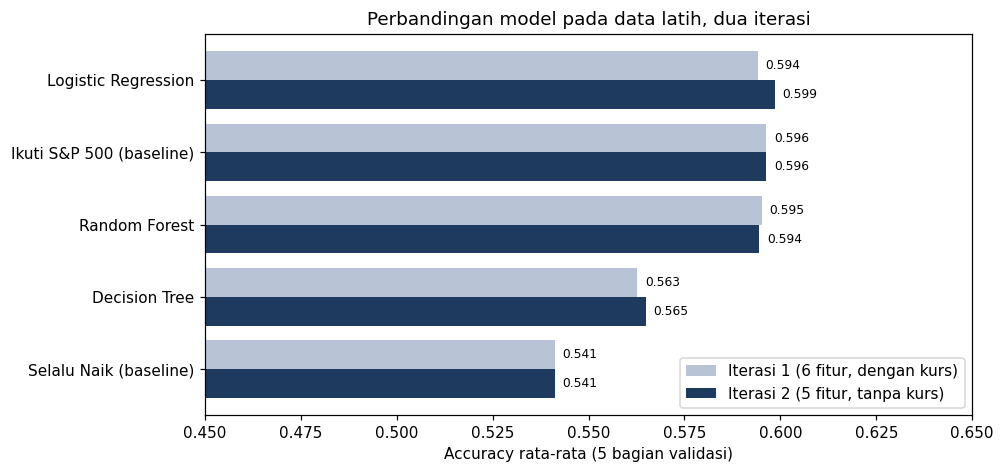

In [6]:
gabung = hasil_cv_1[['Model', 'Accuracy']].merge(hasil_cv_2[['Model', 'Accuracy']], on='Model',
                                                  suffixes=(' iterasi 1', ' iterasi 2'))
gabung = gabung.sort_values('Accuracy iterasi 2').reset_index(drop=True)
posisi = np.arange(len(gabung))
plt.figure(figsize=(9, 4.5))
plt.barh(posisi + 0.2, gabung['Accuracy iterasi 1'], height=0.4, color='#b8c4d6', label='Iterasi 1 (6 fitur, dengan kurs)')
plt.barh(posisi - 0.2, gabung['Accuracy iterasi 2'], height=0.4, color='#1f3a5f', label='Iterasi 2 (5 fitur, tanpa kurs)')
for i, (a, b) in enumerate(zip(gabung['Accuracy iterasi 1'], gabung['Accuracy iterasi 2'])):
    plt.text(a + 0.002, i + 0.2, f'{a:.3f}', va='center', fontsize=8)
    plt.text(b + 0.002, i - 0.2, f'{b:.3f}', va='center', fontsize=8)
plt.yticks(posisi, gabung['Model'])
plt.xlim(0.45, 0.65)
plt.xlabel('Accuracy rata-rata (5 bagian validasi)')
plt.title('Perbandingan model pada data latih, dua iterasi')
plt.legend(loc='lower right')
plt.savefig('../figures/09_perbandingan_model.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Seberapa besar pengaruh kurs di model iterasi 1?

In [7]:
rf_1 = clone(model_list['Random Forest']).fit(latih[FITUR_1], y)
lr_1 = clone(model_list['Logistic Regression']).fit(latih[FITUR_1], y)
pengaruh = pd.DataFrame({'Random Forest: kepentingan fitur': rf_1.feature_importances_,
                         'Logistic Regression: |koefisien|': np.abs(lr_1[-1].coef_[0])}, index=FITUR_1)
pengaruh.sort_values('Random Forest: kepentingan fitur', ascending=False).round(3)

,Random Forest: kepentingan fitur,Logistic Regression: |koefisien|
sp500_chg,0.395,0.361
vix_chg,0.236,0.176
oil_chg,0.111,0.036
gold_chg,0.090,0.113
ihsg_chg,0.086,0.096
usdidr_chg,0.082,0.077


Di **Random Forest** (model terpilih iterasi 1), kurs memiliki tingkat kepentingan **paling kecil** (0,082). Di
Logistic Regression koefisien kurs juga kecil (0,077), hanya di atas minyak.

## 5. Memilih dan menyimpan model terbaik

In [8]:
def simpan_terbaik(hasil_cv, fitur, file):
    kandidat = hasil_cv[~hasil_cv['Model'].str.contains('baseline')]
    nama = kandidat.iloc[0]['Model']
    model = clone(model_list[nama]).fit(latih[fitur], y)   # latih ulang dengan seluruh data latih
    joblib.dump(model, file)
    return {'model': nama, 'fitur': fitur, 'cv_accuracy': round(float(kandidat.iloc[0]['Accuracy']), 4)}

info_1 = simpan_terbaik(hasil_cv_1, FITUR_1, '../models/model_iterasi1.pkl')
info_2 = simpan_terbaik(hasil_cv_2, FITUR_2, '../models/model_terbaik.pkl')
with open('../models/info_model.json', 'w') as f:
    json.dump({**info_2, 'iterasi_1': info_1}, f, indent=2)
print(f"Iterasi 1: {info_1['model']}, accuracy validasi {info_1['cv_accuracy']:.3f}")
print(f"Iterasi 2: {info_2['model']}, accuracy validasi {info_2['cv_accuracy']:.3f} → model akhir")

Iterasi 1: Random Forest, accuracy validasi 0.595
Iterasi 2: Logistic Regression, accuracy validasi 0.599 → model akhir


## Kesimpulan
- **Iterasi 1 (6 fitur, dengan kurs):** Random Forest terbaik (0,595), hampir sama dengan Logistic Regression (0,594).
  Aturan sederhana "Ikuti S&P 500" (0,596) bahkan sedikit lebih tinggi.
- **Iterasi 2 (5 fitur, tanpa kurs):** **Logistic Regression** terbaik (0,599). Mengeluarkan kurs tidak menurunkan
  hasil validasi, jadi model dibuat lebih sederhana.
- Model akhir (iterasi 2) disimpan di `models/model_terbaik.pkl`; model iterasi 1 disimpan di
  `models/model_iterasi1.pkl` untuk dibandingkan di Unit 10.
- Catatan jujur: "Ikuti S&P 500" (0,596) hampir sama dengan model terbaik. Sebagian besar kemampuan model berasal dari
  informasi S&P 500 semalam.